# 01 - Data cleaning and EDA

**Goal:** turn the raw Excel file into one clean table of purchase lines (`config.CLEAN_FILE`)
that every later notebook starts from.

**Steps**
1. Load both sheets of `online_retail_II.xlsx`
2. Apply the cleaning rules in order and record the rows left after each one (a table for the report)
3. Check what the rules removed: duplicates, non-product codes, extreme orders
4. Save the clean transactions (and the cancellations, for the optional `cancel_rate` feature)
5. EDA: revenue and active customers over time, countries, revenue and orders per customer

The cleaning rules themselves live in `src/cleaning.py`; this notebook only calls them and shows the results.

In [1]:
import sys
sys.path.append("..")   # lets the notebook import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
import seaborn as sns

from src import config, cleaning, evaluation

pd.set_option("display.max_columns", 50)
np.random.seed(config.RANDOM_STATE)

evaluation.set_plot_style()          # same fonts/sizes/axes for every figure
GREY = config.COLORS["neutral"]      # EDA plots belong to no module -> neutral grey
INK = config.COLORS["ink"]           # dark colour for lines and text

## 1. Load the raw data

The Excel file has two sheets, `Year 2009-2010` and `Year 2010-2011`. `load_raw()` reads both,
stacks them into one table and renames the columns to snake_case.

Reading Excel is slow (about 3 minutes), so the first run also saves a parquet copy
(`config.RAW_CACHE`); every later run reads that copy in a second or two.

In [2]:
raw = cleaning.load_raw()

print(f"{len(raw):,} rows x {raw.shape[1]} columns")
print("dates:", raw["invoice_date"].min(), "to", raw["invoice_date"].max())
print(f"rows with missing customer_id: {raw['customer_id'].isna().sum():,}")
print(f"unique customers: {raw['customer_id'].nunique():,}")
raw.head()

1,067,371 rows x 8 columns
dates: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
rows with missing customer_id: 243,007
unique customers: 5,942


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 2. Clean

`clean_transactions()` applies the rules from CLAUDE.md Section 7 **in this order**:

1. drop exact duplicate rows
2. drop cancellations (invoice number starts with `C`)
3. drop rows with no `customer_id` (we model per customer, so these rows are unusable), then make the ID an integer
4. drop rows with `quantity <= 0` or `price <= 0`
5. drop non-product stock codes (keep only codes that start with a digit)
6. add `revenue = quantity * price` and make sure `invoice_date` is a datetime

It returns the clean table **and** a step table with the rows left after each rule.
The step table is saved to `reports/results/cleaning_steps.csv` for the report.

In [3]:
clean, steps = cleaning.clean_transactions(raw)
evaluation.save_table(steps, "cleaning_steps")
steps

,step,rows_left,rows_removed,pct_of_raw_left
0,Raw data (both sheets),1067371,0,100.0
1,Drop exact duplicate rows,1033036,34335,96.8
2,Drop cancellations (invoice starts with C),1013932,19104,95.0
3,Drop rows with missing customer_id,779495,234437,73.0
4,Drop quantity <= 0 or price <= 0,779425,70,73.0
5,Drop non-product stock codes,776577,2848,72.8


Quick checks that every rule really holds in the clean table. If any of these fail, the cell stops with an error.

In [4]:
assert clean["customer_id"].notna().all()
assert (clean["quantity"] > 0).all() and (clean["price"] > 0).all()
assert not clean["invoice"].str.startswith("C").any()
assert clean["stock_code"].str.match(r"^\d").all()
assert not clean.duplicated().any()

print(f"clean rows: {len(clean):,}")
print(f"customers: {clean['customer_id'].nunique():,} | invoices: {clean['invoice'].nunique():,} | "
      f"products: {clean['stock_code'].nunique():,} | countries: {clean['country'].nunique()}")
print(f"total revenue: £{clean['revenue'].sum():,.0f}")

clean rows: 776,577
customers: 5,852 | invoices: 36,594 | products: 4,619 | countries: 41
total revenue: £17,068,568


**Biggest loss: missing `customer_id`.** About 23% of all rows have no customer. They are real sales,
but we cannot attach them to anyone, so they are useless for per-customer models. This is a known
property of this dataset and goes in the Limitations section.

## 3. What did the rules remove?

### 3a. Duplicates: the two sheets overlap

Most duplicate rows come from a single month. Looking at that month day by day shows why.

In [5]:
dup_dates = raw.loc[raw.duplicated(), "invoice_date"]
print(f"exact duplicate rows: {len(dup_dates):,}")
dup_dates.dt.to_period("M").value_counts().head(5).to_frame("duplicate_rows")

exact duplicate rows: 34,335


,duplicate_rows
invoice_date,
2010-12,23023
2010-11,1431
2011-11,1368
2010-10,849
2011-10,773


In [6]:
# Duplicates per day, in the month with the most duplicates
top_month = dup_dates.dt.to_period("M").mode()[0]
in_top_month = dup_dates[dup_dates.dt.to_period("M") == top_month]
print("month:", top_month)
in_top_month.dt.day.value_counts().sort_index().to_frame("duplicate_rows").T

month: 2010-12


invoice_date,1,2,3,5,6,7,8,9,10,12,13,14,15,16,17,19,20,21,22,23
duplicate_rows,3152,2150,2219,2830,3926,2980,2686,2901,31,56,7,24,12,19,3,20,3,2,1,1


Days 1-9 of December 2010 have 2,000-4,000 duplicates **each**, and from day 10 the count drops to normal.
Both Excel sheets contain 1-9 Dec 2010 (the first sheet runs to 9 Dec 2010, the second starts on 1 Dec 2010).
Without the duplicate rule those nine days would be counted twice. The remaining duplicates (a few hundred
per month) are identical lines inside the same invoice, which is also safe to drop.

### 3b. Non-product stock codes

Stock codes that do **not** start with a digit, counted in the raw data (before any other rule):

In [7]:
not_product = ~raw["stock_code"].str.match(r"^\d")
(raw[not_product]
    .groupby("stock_code")
    .agg(rows=("invoice", "size"),
         rows_with_customer=("customer_id", "count"),
         example_description=("description", "first"))
    .sort_values("rows", ascending=False)
    .head(15))

,rows,rows_with_customer,example_description
stock_code,,,
POST,2122,2019,POSTAGE
DOT,1446,16,DOTCOM POSTAGE
M,1421,1115,Manual
C2,282,259,CARRIAGE
D,177,174,Discount
S,104,0,SAMPLES
BANK CHARGES,102,38,Bank Charges
ADJUST,67,61,Adjustment by john on 26/01/2010 16
AMAZONFEE,43,0,AMAZON FEE


These are postage (`POST`, `DOT`, `C2`), manual entries and adjustments (`M`, `ADJUST`), discounts (`D`),
bank / Amazon fees, samples and test products: not things a customer chooses to buy.
The `DCGS...` and `gift_0001_...` codes (other web-shop items and gift vouchers) never have a customer ID,
so rule 3 removes them anyway. The only real product the digit rule catches is `SP1002`
(a kids' chalkboard, 2 rows with a customer), which is negligible.

### 3c. Extreme orders

The largest single purchase lines in the clean table:

In [8]:
cols = ["invoice", "stock_code", "description", "quantity", "price", "revenue", "invoice_date", "customer_id"]
clean.nlargest(5, "revenue")[cols]

,invoice,stock_code,description,quantity,price,revenue,invoice_date,customer_id
776116,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,2011-12-09 09:15:00,16446
421802,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,2011-01-18 10:01:00,12346
538376,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.0,2011-06-10 15:28:00,15098
332009,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,15818.4,2010-11-04 11:36:00,15838
169271,511465,15044A,PINK PAPER PARASOL,3500,2.55,8925.0,2010-06-08 12:59:00,18008


In [9]:
# The top two are far bigger than anything else. Were they cancelled?
# Look in the RAW data for lines with the same (or opposite) huge quantity.
top2 = clean.nlargest(2, "revenue")
huge = raw["quantity"].abs() >= top2["quantity"].min()
raw.loc[huge, [c for c in cols if c != "revenue"]]

,invoice,stock_code,description,quantity,price,invoice_date,customer_id
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00,12346.0
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,2011-01-18 10:17:00,12346.0
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00,16446.0
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,2011-12-09 09:27:00,16446.0


**Both huge orders were cancelled about 15 minutes later** (invoices `C541433` and `C581484`, same quantity
with a minus sign). Our rules drop the cancellation line but keep the original purchase line, so the two
purchases stay in the clean table:

- `581483` (9 Dec 2011) is **after** the test label window (which ends 30 Nov 2011), so it touches no
  feature and no label. It only inflates the December 2011 bar in the EDA plots below.
- `541431` (18 Jan 2011, customer 12346) is **before** both cutoffs, so this one customer's `monetary`
  is about £77k too high in both the train and the test table.

> **Open decision (not applied yet):** also drop purchase lines that have an exact matching cancellation
> (same customer, stock code and quantity). This would change the agreed cleaning rules, so it needs
> both of us to agree first.

## 4. Save

- `config.CLEAN_FILE`: the clean purchase lines (input for notebook 02)
- `config.CANCEL_FILE`: one row per cancelled invoice (customer, invoice, date). We keep the **dates** so
  notebook 02 can count only the cancellations **before** each cutoff for the optional `cancel_rate`
  feature. Counting over the whole dataset here would leak the future into the features.

In [10]:
clean.to_parquet(config.CLEAN_FILE, index=False)

cancellations = cleaning.get_cancellations(raw)
cancellations.to_parquet(config.CANCEL_FILE, index=False)

print(f"saved {len(clean):,} clean rows        -> {config.CLEAN_FILE.name}")
print(f"saved {len(cancellations):,} cancelled invoices -> {config.CANCEL_FILE.name}")

saved 776,577 clean rows        -> transactions_clean.parquet
saved 7,901 cancelled invoices -> cancellations.parquet


## 5. EDA

All EDA plots use the clean table. They are saved to `reports/figures/` as PNG (300 dpi) and PDF.

### 5a. Revenue and active customers per month

The dashed lines are the two cutoffs and the shaded areas are the 90-day label windows
(`config.TRAIN_CUTOFF`, `config.TEST_CUTOFF`, `config.HOLDOUT_DAYS`). Features always come from
**before** a dashed line, labels from the shaded window after it.

In [11]:
month = clean["invoice_date"].dt.to_period("M")
monthly = clean.groupby(month).agg(revenue=("revenue", "sum"),
                                   active_customers=("customer_id", "nunique"))
monthly.tail()

,revenue,active_customers
invoice_date,,
2011-08,635514.38,933
2011-09,938752.63,1259
2011-10,1002326.56,1361
2011-11,1136534.00,1660
2011-12,512228.08,614


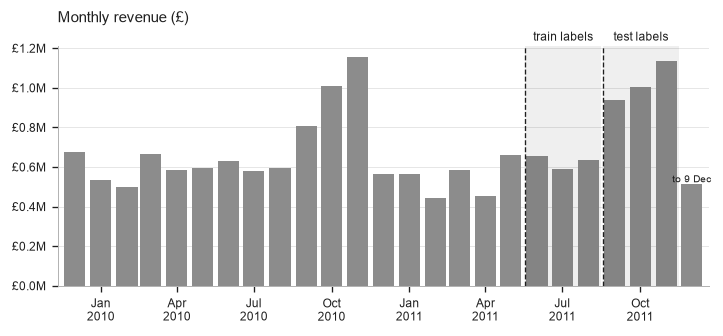

In [12]:
def plot_monthly(values, title, y_format):
    # One bar per month, with the two cutoffs and their 90-day label windows marked.
    fig, ax = plt.subplots(figsize=(7, 2.6))
    # Put each bar in the middle of its month, so the month ticks sit under the bars.
    mid_month = values.index.to_timestamp() + pd.Timedelta(days=14)
    ax.bar(mid_month, values.values, width=25, color=GREY)

    window = pd.Timedelta(days=config.HOLDOUT_DAYS)
    for cutoff, name in [(config.TRAIN_CUTOFF, "train labels"), (config.TEST_CUTOFF, "test labels")]:
        ax.axvspan(cutoff, cutoff + window, color=INK, alpha=0.07, linewidth=0)
        ax.axvline(cutoff, color=INK, linewidth=0.8, linestyle="--")
        ax.text(cutoff + window / 2, 1.01, name, transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", fontsize=7)

    # The last month is incomplete: the data stops at config.DATA_END.
    ax.text(mid_month[-1], values.iloc[-1], f"to {config.DATA_END.day} {config.DATA_END:%b}",
            ha="center", va="bottom", fontsize=6)

    ax.set_title(title, loc="left", pad=14)
    ax.yaxis.set_major_formatter(y_format)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10], bymonthday=15))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.margins(x=0.01)
    return fig


fig = plot_monthly(monthly["revenue"], "Monthly revenue (£)",
                   mtick.FuncFormatter(lambda v, _: f"£{v / 1e6:.1f}M"))
evaluation.save_fig(fig, "eda_monthly_revenue")
plt.show()

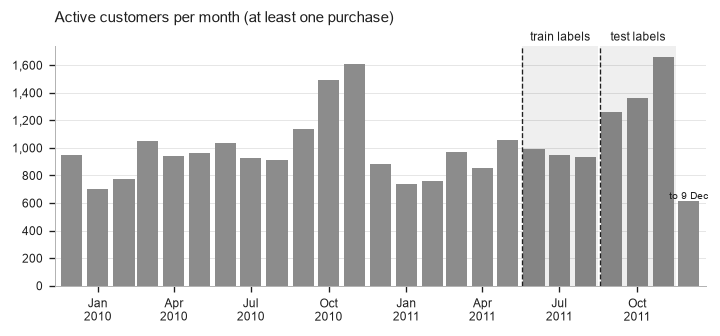

In [13]:
fig = plot_monthly(monthly["active_customers"], "Active customers per month (at least one purchase)",
                   mtick.StrMethodFormatter("{x:,.0f}"))
evaluation.save_fig(fig, "eda_monthly_customers")
plt.show()

### 5b. Countries

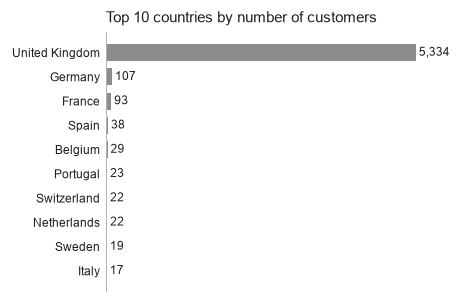

UK share of customers: 91%


In [14]:
customers_per_country = clean.groupby("country")["customer_id"].nunique().sort_values(ascending=False)
top10 = customers_per_country.head(10).iloc[::-1]       # reversed so the largest bar is on top

fig, ax = plt.subplots(figsize=(3.5, 2.8))
ax.barh(top10.index, top10.values, color=GREY, height=0.7)
for y, value in enumerate(top10.values):
    ax.text(value, y, f" {value:,}", va="center", fontsize=7)   # value at the end of each bar
ax.set_title("Top 10 countries by number of customers", loc="left")
ax.tick_params(axis="y", length=0)
ax.grid(False)
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
evaluation.save_fig(fig, "eda_top_countries")
plt.show()

uk_share = customers_per_country.get("United Kingdom", 0) / clean["customer_id"].nunique()
print(f"UK share of customers: {uk_share:.0%}")

### 5c. Revenue and orders per customer (whole period)

In [15]:
per_customer = clean.groupby("customer_id").agg(revenue=("revenue", "sum"),
                                                orders=("invoice", "nunique"))
per_customer.describe().round(1)

,revenue,orders
count,5852.0,5852.0
mean,2916.7,6.3
std,14306.9,12.7
min,3.0,1.0
25%,339.6,1.0
50%,856.0,3.0
75%,2241.0,7.0
max,580987.0,373.0


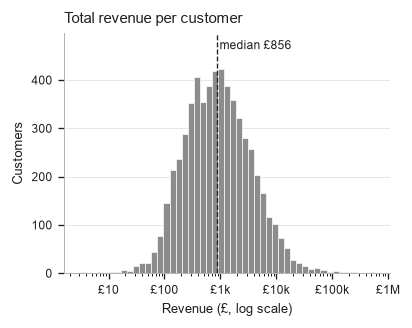

In [16]:
def short_pounds(value, _):
    # Axis label like £10, £1k, £100k, £1M instead of long numbers.
    if value >= 1e6:
        return f"£{value / 1e6:g}M"
    if value >= 1e3:
        return f"£{value / 1e3:g}k"
    return f"£{value:g}"


# Revenue is extremely skewed, so use log-spaced bins and a log x-axis.
bins = np.logspace(np.log10(per_customer["revenue"].min()), np.log10(per_customer["revenue"].max()), 50)

fig, ax = plt.subplots(figsize=(3.5, 2.6))
ax.hist(per_customer["revenue"], bins=bins, color=GREY, edgecolor="white", linewidth=0.4)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(short_pounds))
ax.set_ylim(0, ax.get_ylim()[1] * 1.12)      # headroom for the median label

median = per_customer["revenue"].median()
ax.axvline(median, color=INK, linewidth=0.8, linestyle="--")
ax.text(median, 0.97, f" median £{median:,.0f}", transform=ax.get_xaxis_transform(), va="top", fontsize=7)

ax.set_title("Total revenue per customer", loc="left")
ax.set_xlabel("Revenue (£, log scale)")
ax.set_ylabel("Customers")
evaluation.save_fig(fig, "eda_revenue_per_customer")
plt.show()

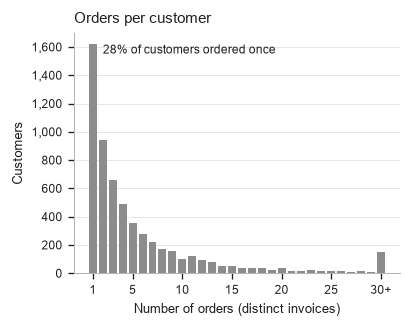

In [17]:
# Number of orders (distinct invoices) per customer; everything above CAP goes in one "CAP+" bar.
CAP = 30
order_counts = per_customer["orders"].clip(upper=CAP).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(3.5, 2.6))
ax.bar(order_counts.index, order_counts.values, color=GREY, width=0.8)
ticks = [1, 5, 10, 15, 20, 25, CAP]
ax.set_xticks(ticks, [str(t) for t in ticks[:-1]] + [f"{CAP}+"])

one_order = (per_customer["orders"] == 1).mean()
ax.text(2, order_counts.loc[1], f"{one_order:.0%} of customers ordered once", va="top", fontsize=7)

ax.set_title("Orders per customer", loc="left")
ax.set_xlabel("Number of orders (distinct invoices)")
ax.set_ylabel("Customers")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
evaluation.save_fig(fig, "eda_orders_per_customer")
plt.show()

## 6. What we learned (feeds the later notebooks)

- **Clean data:** 776,577 purchase lines (72.8% of the raw rows), 5,852 customers, 36,594 invoices,
  4,619 products, 41 countries, £17.07M revenue. The biggest loss is rows without a customer ID.
- **Strong seasonality:** revenue and active customers peak every **September-November** (over £1.1M in
  November of both years), while June-August is quiet (about £0.6M a month). Our **train** labels fall in
  the quiet season and the **test** labels in the peak season, so we should expect a **lower churn rate and
  higher spend in the test table** than in the train table. Notebook 02 must print both, and the report
  should discuss this as a distribution shift.
- **Mostly UK:** 91% of customers are in the United Kingdom, so `is_uk` is a very unbalanced feature.
- **Revenue per customer is extremely right-skewed:** median £856, mean £2,917, maximum about £581k
  (wholesalers). This supports the `log1p` transform for segmentation and CLV.
- **Many one-time buyers:** 28% of customers ordered only once (median 3 orders, maximum 373). For them
  `mean_interpurchase_days` is undefined, which is why notebook 02 needs the `is_single_order` flag.
- **Data issues to remember:** the two sheets overlap on 1-9 Dec 2010 (handled by the duplicate rule), and
  two huge orders were cancelled straight away (section 3c, open decision).